C:\Users\mordi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Network Event Classification:
   Packets  Data_Size  Cluster  Category
0       10         20        0    Normal
1       12         25        0    Normal
2       15         22        0    Normal
3       11         18        0    Normal
4      100        200        1  Abnormal
5      120        220        1  Abnormal
6      110        210        1  Abnormal
7      130        250        1  Abnormal


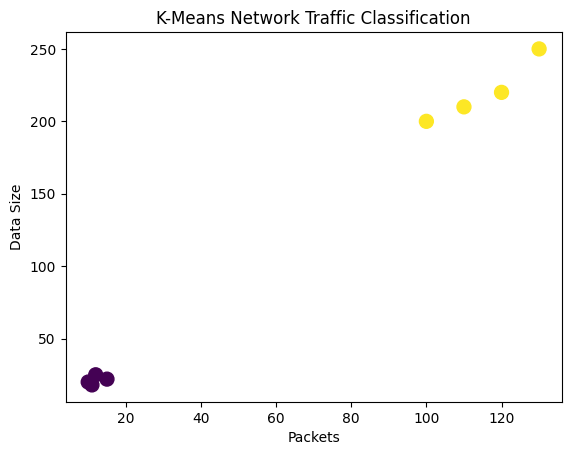

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Create Dataset
data = pd.DataFrame({
    'Packets': [10, 12, 15, 11, 100, 120, 110, 130],
    'Data_Size': [20, 25, 22, 18, 200, 220, 210, 250]
})

# Feature Scaling
scaler = StandardScaler()
X = scaler.fit_transform(data)

# Apply K-Means Clustering
model = KMeans(n_clusters=2, random_state=42, n_init=10)
data['Cluster'] = model.fit_predict(X)

# Identify Abnormal Cluster
abnormal = data.groupby('Cluster')['Packets'].mean().idxmax()

# Classify Network Events
data['Category'] = data['Cluster'].apply(
    lambda x: 'Abnormal' if x == abnormal else 'Normal'
)

# Display Results
print("Network Event Classification:")
print(data)

# Visualize Clusters
plt.scatter(data['Packets'], data['Data_Size'],
            c=data['Cluster'], s=100)

plt.xlabel("Packets")
plt.ylabel("Data Size")
plt.title("K-Means Network Traffic Classification")
plt.show()